# LIBs

In [1]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix ,ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.preprocessing import StandardScaler

# import tensorflow as tf
import numpy as np
from itertools import product
import joblib
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import SGDRegressor

import matplotlib.pyplot as plt
# from tensorflow.keras import Sequential
import warnings
warnings.filterwarnings('ignore')


# Func

#### Model Evaluation

In [2]:
def model_evaluation(y_true, y_pred):
    print("Accuracy:", accuracy_score(y_true, y_pred))
    
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))
    
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))


#### flatten fun


In [3]:
def flatten_data(x_train, x_test):
    n_train = x_train.shape[0]
    n_test = x_test.shape[0]

    flat_train = x_train.reshape(n_train, x_train[0].size)
    flat_test  = x_test.reshape(n_test,  x_test[0].size)

    return flat_train, flat_test

#### K-Fold

In [4]:
def kfold_cross_validation(X, y, params=None, model_type=""):

    k = 5
    n = X.shape[0]
    fold_size = n // k
    
    acc_list = []
    f1_list = []
    precision_list = []
    recall_list = []
    
    for i in range(k):
        val_start = i * fold_size
        val_end = (i + 1) * fold_size if i != k - 1 else n
        
        X_val = X[val_start:val_end]
        y_val = y[val_start:val_end]
        
        X_train = np.concatenate([X[:val_start], X[val_end:]], axis=0)
        y_train = np.concatenate([y[:val_start], y[val_end:]], axis=0)
        
        if model_type == "logreg":
            thetas = train_ova_logreg(X_train, y_train, **params)
            y_pred = predict_ova_logreg(thetas, X_val)
        
        elif model_type == "linear":
            thetas = train_linear_ova(X_train, y_train, **params)
            y_pred = predict_linear_ova(X_val, thetas)
        
        elif model_type == "naive":
            model = GaussianNB()
            model.fit(X_train, y_train)
            y_pred = model.predict(X_val)
        
        else:
            raise ValueError("Unknown model_type. Use 'logreg', 'linear', or 'naive'.")
        
        acc_list.append(accuracy_score(y_val, y_pred))
        f1_list.append(f1_score(y_val, y_pred, average="macro"))
        precision_list.append(precision_score(y_val, y_pred, average="macro"))
        recall_list.append(recall_score(y_val, y_pred, average="macro"))
    
    return {
        "acc_mean": np.mean(acc_list), "acc_std": np.std(acc_list),
        "f1_mean": np.mean(f1_list), "f1_std": np.std(f1_list),
        "precision_mean": np.mean(precision_list), "precision_std": np.std(precision_list),
        "recall_mean": np.mean(recall_list), "recall_std": np.std(recall_list),
    }


#### tune Neural Network hyperparameter

In [7]:

def grid_search_mlp_simple(x_train, y_train, x_test, y_test, val_split=0.1):
    num_classes = 10

    grid = {
        "epochs": [30,60],
        "n_layers": [2, 3],
        "layer_size": [256 , 512],
        "l2": [1e-3],
        "lr": [0.001 , 0.0003],
        "opt": ["SGD", "RMSprop"],
        "batch": [32, 64],
        "act": ["sigmoid", "relu"],
    }

    def make_opt(name, lr):
        if name == "SGD":
            return tf.keras.optimizers.SGD(learning_rate=lr)
        if name == "RMSprop":
            return tf.keras.optimizers.RMSprop(learning_rate=lr)
    def build_model(n_layers, layer_size, act, l2v, lr, opt_name):
        reg = tf.keras.regularizers.l2(l2v) 

        model = tf.keras.Sequential()
        model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))

        for i in range(n_layers):
            model.add(tf.keras.layers.Dense(layer_size, activation=act, kernel_regularizer=reg))

        model.add(tf.keras.layers.Dense(num_classes, activation="softmax"))

        model.compile(
            optimizer=make_opt(opt_name, lr),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )
        return model

    best_acc, best_params = -1.0, None
    all_results = {}

    combos = product(
        grid["epochs"], grid["n_layers"], grid["layer_size"], grid["l2"],
        grid["lr"], grid["opt"], grid["batch"], grid["act"]
    )

    for epochs, n_layers, layer_size, l2v, lr, opt_name, batch, act in combos:
        params = {
            "epochs": epochs, "n_layers": n_layers, "layer_size": layer_size, "l2": l2v,
            "lr": lr, "opt": opt_name, "batch": batch, "act": act
        }
        key = (epochs, n_layers, layer_size, l2v, lr, opt_name, batch, act)

        tf.keras.backend.clear_session()
        model = build_model(n_layers, layer_size, act, l2v, lr, opt_name)

        h = model.fit(x_train, y_train,validation_split=val_split,epochs=epochs,batch_size=batch,verbose=0)
    
        val_acc = float(max(h.history["val_accuracy"]))
        val_loss = float(min(h.history["val_loss"])) 

        all_results[key] = {
            "params": params,
            "best_val_accuracy": val_acc,
            "best_val_loss": val_loss,
            "history": h.history,
        }

        if val_acc > best_acc:
            best_acc = val_acc
            best_params = params

    final_model = build_model(
        best_params["n_layers"], best_params["layer_size"], best_params["act"],
        best_params["l2"], best_params["lr"], best_params["opt"]
    )
    final_model.fit(
        x_train, y_train,
        epochs=best_params["epochs"],
        batch_size=best_params["batch"],
        verbose=0
    )
    test_loss, test_acc = final_model.evaluate(x_test, y_test, verbose=0)

    return best_params, best_acc, float(test_acc), final_model, all_results

# tune hyper


In [5]:
def tune_hyperparameters(X, y, model_type):
    best_f1 = -1
    best_params = None
    best_result = None
    
    learning_rate = [0.01, 0.001]
    epochs = [40, 80]
    l2 = [0.01, 0.001]
    batch_sizes = [32, 64]
    tol_list = [1e-5 , 1e-3, 1e-4]   

    tol_values = tol_list if model_type == "logreg" else [None]

    for lr, ep, batch_size, l2_val, tol in product(
        learning_rate, epochs, batch_sizes, l2, tol_values
    ):
        params = {
            "learning_rate": lr,
            "epochs": ep,
            "batch_size": batch_size,
            "l2_lambda": l2_val
        }

        if tol is not None:
            params["tol"] = tol

        kfold_result = kfold_cross_validation(X, y, params, model_type=model_type)
        
        if kfold_result["f1_mean"] > best_f1:
            best_f1 = kfold_result["f1_mean"]
            best_params = params
            best_result = kfold_result

            msg = (
                f"New best F1: {best_f1:.4f} | "
                f"LR={lr}, Epochs={ep}, Batch_size={batch_size}, L2={l2_val}"
            )
            if tol is not None:
                msg += f", tol={tol}"
            print(msg)
    
    return best_params, best_result


# batches


In [ ]:
def create_batches(X, y, batch_size):
    n_samples = X.shape[0]
    for i in range(0, n_samples, batch_size):
        X_batch = X[i:i + batch_size]
        y_batch = y[i:i + batch_size]
        yield X_batch, y_batch
        

# logistic

In [ ]:
def add_bias(X):
    m = X.shape[0]
    return np.hstack([np.ones((m, 1)), X])

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def train_ova_logreg(X, y, learning_rate=0.01, tol=0.001, epochs=80, batch_size=32 , l2_lambda=0.001, num_classes=10):

    X = add_bias(X)
    m, n = X.shape  # X shape: (10000, 784 + 1) , m = num of samples(imgs), n = num of features + 1 for bias

    thetas = np.zeros((num_classes, n))

    for c in range(num_classes):
        y_bin = (y == c).astype(np.float32)
        theta = np.zeros(n)

        for epoch in range(epochs):

            idx = np.random.permutation(m)
            X_shuffled = X[idx]
            y_shuffled = y_bin[idx]

            theta_prev = theta.copy()

            for X_batch, y_batch in create_batches(
                X_shuffled, y_shuffled, batch_size
            ):
                z = X_batch @ theta
                h = sigmoid(z)

                grad = (X_batch.T @ (h - y_batch)) / len(X_batch)
                grad += (l2_lambda / m) * theta

                theta -= learning_rate * grad

            if np.linalg.norm(theta - theta_prev, ord=1) < tol:
                break

        thetas[c] = theta
    return thetas


In [ ]:
def predict_ova_logreg(thetas, X):
    X = add_bias(X)
    z = X.dot(thetas.T)  
    h = sigmoid(z)
    return np.argmax(h, axis=1)

# linear

In [ ]:
def train_linear_ova(X_train, y_train, learning_rate, epochs, batch_size, l2_lambda):
    n_samples, n_features = X_train.shape
    n_classes = 10

    X_bias = np.hstack([np.ones((n_samples, 1)), X_train])
    class_weights = np.zeros((n_classes, n_features + 1))

    for c in range(n_classes):
        y_binary = (y_train == c).astype(np.float32)
        w = np.zeros(n_features + 1)

        for epoch in range(epochs):
            idx = np.random.permutation(n_samples)
            X_shuffled = X_bias[idx]
            y_shuffled = y_binary[idx]

            for X_batch, y_batch in create_batches(X_shuffled, y_shuffled, batch_size):
                preds = X_batch @ w
                errors = preds - y_batch

                grad = (X_batch.T @ errors) / len(X_batch)
                grad += l2_lambda * w  

                w -= learning_rate * grad

        class_weights[c] = w

    return class_weights


In [ ]:
def predict_linear_ova(X, class_weights):
    n_samples = X.shape[0]
    X_bias = np.hstack([np.ones((n_samples, 1)), X])

    scores = X_bias @ class_weights.T
    return np.argmax(scores, axis=1)


# DATA

In [22]:

data_dir = r"D:\proj antar\10000\10000"  
X = []
y = []
target_size = (28, 28)
for label in range(10):
    path = os.path.join(data_dir, str(label))
    
    for name in os.listdir(path): 
        
        img_path = os.path.join(path, name)
        img = Image.open(img_path).convert("L") 
        img = img.resize(target_size)
        img_array = np.array(img, dtype="float32") 
        
        X.append(img_array)
        y.append(label)

X = np.array(X, dtype="float32") /255.0 #normalization
y = np.array(y, dtype="int64")

print("X shape:", X.shape) 
print("y shape:", y.shape)


X shape: (10000, 28, 28)
y shape: (10000,)


# Models

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,stratify=y, random_state=42)

## Logistic Classification

#### tune hyperparameter 

In [ ]:
X_train_lr, X_test_lr = flatten_data(X_train, X_test)



In [ ]:
best_params, best_result = tune_hyperparameters(
    X_train_lr, y_train, model_type="logreg"
)



In [ ]:
print("Best Hyperparameters:", best_params)

In [ ]:

print(
    f"Accuracy = {best_result['acc_mean']:.4f} (± {best_result['acc_std']:.4f})\n"
    f"Precision = {best_result['precision_mean']:.4f} (± {best_result['precision_std']:.4f})\n"
    f"Recall = {best_result['recall_mean']:.4f} (± {best_result['recall_std']:.4f})\n"
    f"F1-score = {best_result['f1_mean']:.4f} (± {best_result['f1_std']:.4f})"
)


In [ ]:
Final_thetas = train_ova_logreg(X_train_lr, y_train , **best_params)


In [ ]:
y_pred = predict_ova_logreg(Final_thetas, X_test_lr)

In [ ]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="macro"))
print("Recall   :", recall_score(y_test, y_pred, average="macro"))
print("F1-score :", f1_score(y_test, y_pred, average="macro"))
model_evaluation(y_test, y_pred)

#### training model

In [63]:
log_reg = LogisticRegression(C=best_c,tol=best_tol,multi_class='multinomial',random_state=42)
log_reg.fit(X_train_lr, y_train)


LogisticRegression(C=0.1, multi_class='multinomial', random_state=42,
                   tol=0.0005)

#### testing model

In [64]:
y_pred = log_reg.predict(X_test_lr)
print("variance :",stdd)
model_evaluation(y_test,y_pred)
f1 = f1_score(y_test, y_pred, average="macro")
print("F1 :", f1)

variance : 0.007490217309597849
Accuracy: 0.768

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.82      0.80       200
           1       0.75      0.81      0.78       200
           2       0.81      0.73      0.77       200
           3       0.80      0.77      0.79       200
           4       0.74      0.77      0.75       200
           5       0.79      0.79      0.79       200
           6       0.82      0.85      0.84       200
           7       0.71      0.74      0.73       200
           8       0.75      0.64      0.69       200
           9       0.74      0.77      0.75       200

    accuracy                           0.77      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.77      0.77      0.77      2000


Confusion Matrix:
[[164   8   1   1   6   4   5   1   4   6]
 [  5 162   5   5   1   3   1  12   6   0]
 [  5   7 147   9   6   4   2   8   2  10]
 [  7   3   8 154   8

Text(0.5, 1.0, 'Confusion Matrix - Logistic Regression')

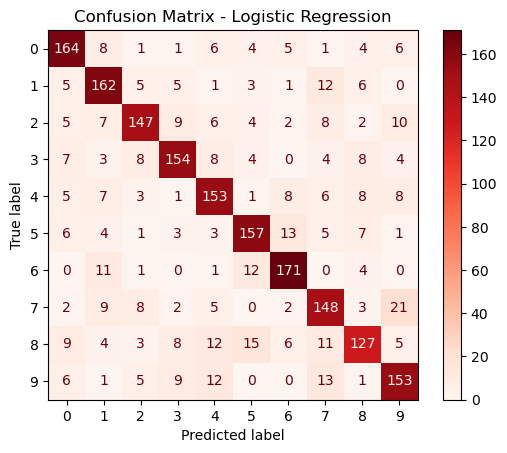

In [65]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
)
disp.plot(cmap="Reds")
plt.title("Confusion Matrix - Logistic Regression")


## Deep Learning

In [ ]:
params, val_acc, test_acc, best_model, all_results = grid_search_mlp_simple(X_train, y_train, X_test, y_test, val_split=0.1)

In [ ]:
params


In [93]:

model3 = Sequential()
#### Input layer
model3.add(tf.keras.layers.Flatten(input_shape=(28,28)))
#### Hidden layer
model3.add(tf.keras.layers.Dense(512, activation='relu',kernel_regularizer=tf.keras.regularizers.l2(0.001)))
model3.add(tf.keras.layers.Dense(512, activation='relu',kernel_regularizer=tf.keras.regularizers.l2(0.001)))
model3.add(tf.keras.layers.Dense(512, activation='relu',kernel_regularizer=tf.keras.regularizers.l2(0.001)))
#### Output layer
model3.add(tf.keras.layers.Dense(10,activation=tf.keras.activations.softmax)) 
model3.summary()
model3.compile(
    optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0003),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

model3.fit(
    X_train, y_train,
    epochs=60,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    shuffle=True
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 932,362 (3.56 MB)

 Trainable params: 932,362 (3.56 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
225/225 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3072 - loss: 3.2696 - val_accuracy: 0.4275 - val_loss: 2.7248
Epoch 2/60
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5113 - loss: 2.4040 - val_accuracy: 0.4737 - val_loss: 2.3789
Epoch 3/60
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5683 - loss: 2.0390 - val_accuracy: 0.5138 - val_loss: 2.0450
Epoch 4/60
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6168 - loss: 1.8365 - val_accuracy: 0.6988 - val_loss: 1.5502
Epoch 5/60
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6506 - loss: 1.6803 - val_accuracy: 0.6388 - val_loss: 1.6300
Epoch 6/60
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6665 - loss: 1.5773 - val_accuracy: 0.7075 - val_loss: 1.4488
Epoch 7/60
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6869 - loss: 1.5022 - val_accuracy: 0.5950 - val_loss: 1.7601
Epoch 8/60
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6976 - loss: 1.4307 - val_accuracy: 0.

In [92]:
DL_model.evaluate(X_test, y_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8690 - loss: 0.7285


[0.7284789681434631, 0.8690000176429749]

In [14]:
import csv

csv_path = "grid_summary.csv"

with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["best_val_accuracy","best_val_loss","epochs","n_layers","layer_size","l2","lr","opt","batch","act"])
    
    for r in all_results.values():
        p = r["params"]
        writer.writerow([
            r["best_val_accuracy"],
            r["best_val_loss"],
            p["epochs"], p["n_layers"], p["layer_size"], p["l2"],
            p["lr"], p["opt"], p["batch"], p["act"]
        ])

print("Saved CSV to:", csv_path)


Saved CSV to: grid_summary.csv


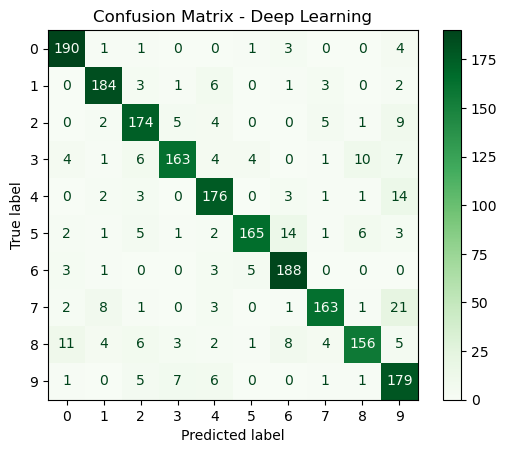

In [104]:
cm_dl = confusion_matrix(y_test, y_pred_dl)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dl,
    display_labels=list(range(10))
)

disp.plot(cmap="Greens")
plt.title("Confusion Matrix - Deep Learning")
plt.show()

## Linear

In [ ]:
X_train_flat,X_test_flat=flatten_data(X_train, X_test)

In [ ]:
best_params, best_result = tune_hyperparameters(
    X_train_flat, y_train, model_type="linear"
)


In [ ]:
print("Best Hyperparameters:", best_params)

In [ ]:

print(
    f"Accuracy = {best_result['acc_mean']:.4f} (± {best_result['acc_std']:.4f})\n"
    f"Precision = {best_result['precision_mean']:.4f} (± {best_result['precision_std']:.4f})\n"
    f"Recall = {best_result['recall_mean']:.4f} (± {best_result['recall_std']:.4f})\n"
    f"F1-score = {best_result['f1_mean']:.4f} (± {best_result['f1_std']:.4f})"
)


{'acc_mean': np.float64(0.715875),
 'acc_std': np.float64(0.0054572199882358015),
 'f1_mean': np.float64(0.7133563741961165),
 'f1_std': np.float64(0.005445903373504785),
 'precision_mean': np.float64(0.7231863106058525),
 'precision_std': np.float64(0.00539507250829083),
 'recall_mean': np.float64(0.7158749999999999),
 'recall_std': np.float64(0.0054572199882357494)}

In [38]:
best_params

{'eta0': 0.0001, 'max_iter': 500, 'tol': 1e-05}

In [ ]:
linear_trian_model = train_linear_ova(
    X_train_flat, y_train,
    **best_params
)


In [ ]:
y_pred_linear= predict_linear_ova(X_test_flat, linear_trian_model)

In [ ]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="macro"))
print("Recall   :", recall_score(y_test, y_pred, average="macro"))
print("F1-score :", f1_score(y_test, y_pred, average="macro"))
print(classification_report(y_test, y_pred))

Accuracy: 0.715
F1: 0.7126158054851481
              precision    recall  f1-score   support

           0       0.77      0.79      0.78       200
           1       0.76      0.72      0.74       200
           2       0.68      0.81      0.74       200
           3       0.78      0.71      0.74       200
           4       0.59      0.83      0.69       200
           5       0.91      0.53      0.67       200
           6       0.62      0.90      0.73       200
           7       0.79      0.61      0.69       200
           8       0.73      0.55      0.63       200
           9       0.73      0.70      0.72       200

    accuracy                           0.71      2000
   macro avg       0.74      0.72      0.71      2000
weighted avg       0.74      0.71      0.71      2000



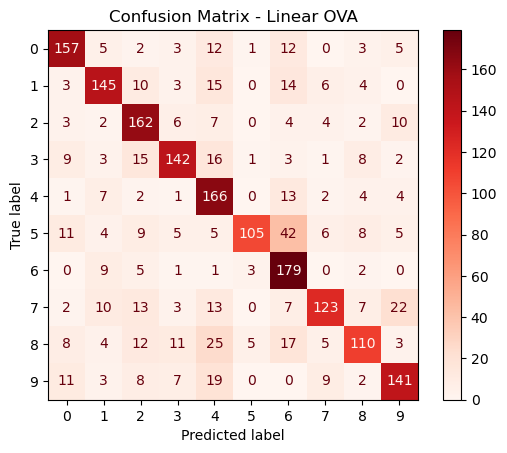

In [61]:

cm_linear = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_linear,
    display_labels=list(range(10))
)

disp.plot(cmap="Reds")
plt.title("Confusion Matrix - Linear OVA")
plt.show()


## Naive Bayes

In [ ]:
X_train_nv, X_test_nv = flatten_data(X_train, X_test)

nv_model = GaussianNB()
nv_model.fit(X_train_nv, y_train)

y_pred_nb = nv_model.predict(X_test_nv)
model_evaluation( y_test, y_pred_nb)
acc_nb = kfold_cross_validation(
    X_train_nv,
    y_train,
    params=None,
    model_type="naive"
)

print("Accuracy :", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb, average="macro"))
print("Recall   :", recall_score(y_test, y_pred_nb, average="macro"))
print("F1-score :", f1_score(y_test, y_pred_nb, average="macro"))


Accuracy: 0.5115

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.59      0.58       200
           1       0.32      0.67      0.43       200
           2       0.57      0.35      0.43       200
           3       0.49      0.61      0.54       200
           4       0.54      0.43      0.48       200
           5       0.64      0.45      0.53       200
           6       0.68      0.58      0.63       200
           7       0.57      0.50      0.53       200
           8       0.47      0.39      0.42       200
           9       0.59      0.56      0.57       200

    accuracy                           0.51      2000
   macro avg       0.54      0.51      0.51      2000
weighted avg       0.54      0.51      0.51      2000


Confusion Matrix:
[[118  26   3   8  15   7  11   2   2   8]
 [  2 133   2  19   5   5   7  20   4   3]
 [  4  40  70  42   6   1   1  11  16   9]
 [ 11  25  11 122   7   2   0   5   6  11]
 [ 18  28

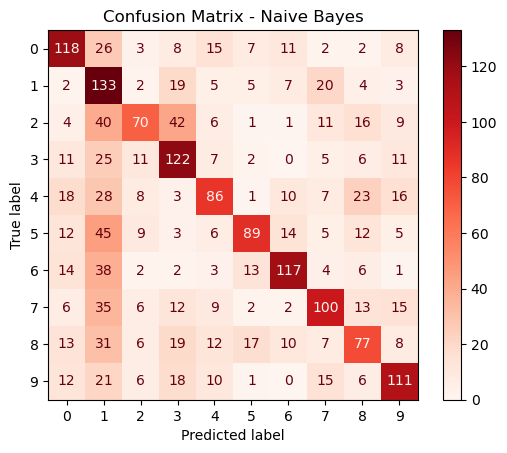

In [47]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=list(range(10))
)
disp.plot(cmap="Reds")
plt.title("Confusion Matrix - Naive Bayes")
plt.show()


## Save Models

In [ ]:
joblib.dump(log_reg, "log_reg.joblib")
joblib.dump(nv_model, "nv_model.joblib")    #NV
#model3.save("best_model.keras")   #DL

#DL_model = tf.keras.models.load_model("best_model.keras")  #DL
log_reg_loaded = joblib.load("log_reg.joblib")
nv_model_loaded = joblib.load("nv_model.joblib")  


In [90]:
DL_model = tf.keras.models.load_model("best_model.keras")  #DL


# comparison

In [97]:
y_pred_dl = np.argmax(DL_model.predict(X_test), axis=1)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


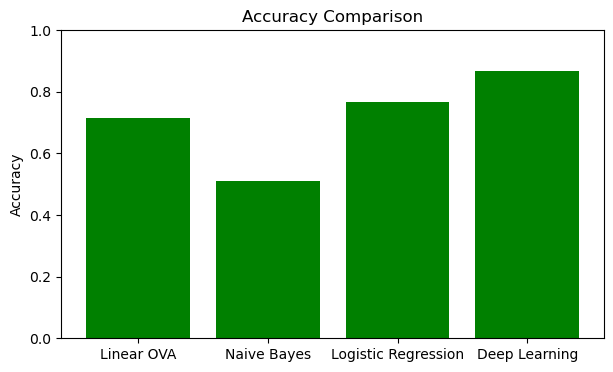

In [98]:
models = ["Linear OVA", "Naive Bayes", "Logistic Regression", "Deep Learning"]

accuracies = [
    accuracy_score(y_test, y_pred_linear),  # Linear
    accuracy_score(y_test, y_pred_nb),      # Naive
    accuracy_score(y_test, y_pred),          # Logistic
    accuracy_score(y_test, y_pred_dl)        # Deep Learning
]

plt.figure(figsize=(7,4))
plt.bar(models, accuracies, color="green")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")
plt.ylim(0, 1)
plt.show()


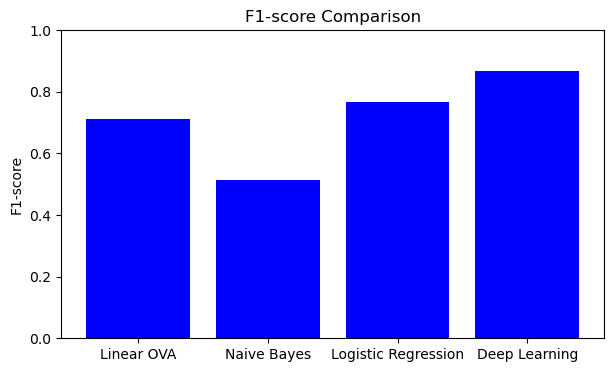

In [103]:

models = ["Linear OVA", "Naive Bayes", "Logistic Regression", "Deep Learning"]

f1_scores = [
    f1_score(y_test, y_pred_linear, average="macro"),  # Linear
    f1_score(y_test, y_pred_nb, average="macro"),      # Naive
    f1_score(y_test, y_pred, average="macro"),         # Logistic
    f1_score(y_test, y_pred_dl, average="macro")       # Deep Learning
]

plt.figure(figsize=(7,4))
plt.bar(models, f1_scores, color="blue")
plt.ylabel("F1-score")
plt.title("F1-score Comparison")
plt.ylim(0, 1)
plt.show()


In [112]:
f1_scores = [
    f1_score(y_test, y_pred_linear, average="macro"),  # Linear
    f1_score(y_test, y_pred_nb, average="macro"),      # Naive
    f1_score(y_test, y_pred, average="macro"),         # Logistic
    f1_score(y_test, y_pred_dl, average="macro")       # Deep Learning
]
f1_scores

[0.7126158054851481,
 0.5143586103652963,
 0.7673204666159208,
 0.8690696848019815]

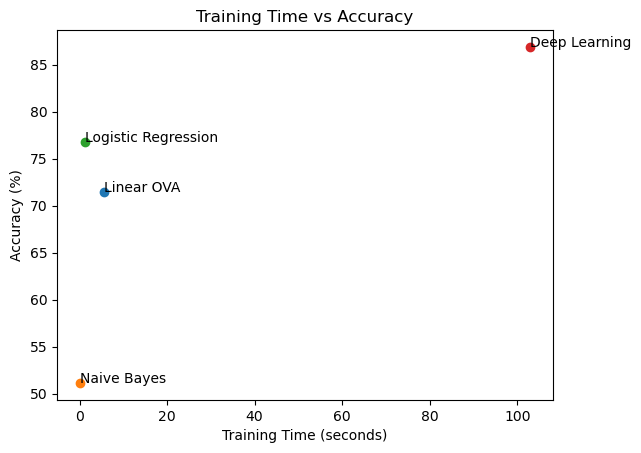

In [110]:
acc_linear = accuracy_score(y_test, y_pred_linear) * 100
acc_nb = accuracy_score(y_test, y_pred_nb) * 100
acc_log = accuracy_score(y_test, y_pred) * 100
acc_dl = accuracy_score(y_test, y_pred_dl) * 100

time_linear = 5.6
time_nb = 0.00
time_log = 1.2
time_dl = 103

plt.scatter(time_linear, acc_linear)
plt.scatter(time_nb, acc_nb)
plt.scatter(time_log, acc_log)
plt.scatter(time_dl, acc_dl)

plt.text(time_linear, acc_linear, "Linear OVA")
plt.text(time_nb, acc_nb, "Naive Bayes")
plt.text(time_log, acc_log, "Logistic Regression")
plt.text(time_dl, acc_dl, "Deep Learning")

plt.xlabel("Training Time (seconds)")
plt.ylabel("Accuracy (%)")
plt.title("Training Time vs Accuracy")

plt.show()


In [123]:
print("log std:",log_std,"bias std",nb_std,"lin std",linear_std)

log std: 0.007490217309597849 bias std 0.009493660450922214 lin std 0.005445903373504785
